In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [2]:
columns = [
    'variance',
    'skewness',
    'curtosis',
    'entropy',
    'class'
]
df = pd.read_csv(r'D:\Desktop\data_banknote_authentication.txt', names=columns)
df.head()

,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1372, 5)


In [4]:
print("\nDataset Information:")
df.info()
print("\nStatistical Summary:")
display(df.describe())


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Statistical Summary:


,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [5]:
print("\nMissing Values:")
print(df.isnull().sum())
print("\nClass Distribution:")
print(df['class'].value_counts())


Missing Values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Class Distribution:
class
0    762
1    610
Name: count, dtype: int64


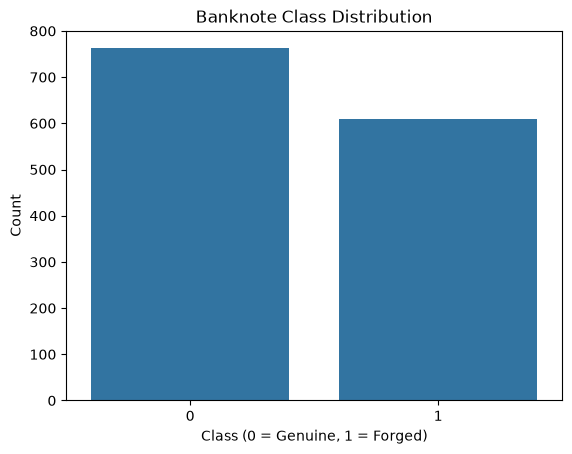

In [6]:
sns.countplot(data=df, x='class')
plt.title("Banknote Class Distribution")
plt.xlabel("Class (0 = Genuine, 1 = Forged)")
plt.ylabel("Count")
plt.show()

In [7]:
X = df.drop('class', axis=1).values
y = df['class'].values
print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (1372, 4)
Target Shape: (1372,)


In [8]:
X_train, X_test, y_train, y_test = train_test_split ( X, y, test_size=0.2, random_state=42, stratify=y )
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1097, 4)
Testing Data: (275, 4)


In [9]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Training Data After Scaling:")
print(X_train[:5])

Training Data After Scaling:
[[ 0.39687699  0.05746643 -1.03953765  0.51951506]
 [-0.38173115 -0.22255311 -0.41215984  0.26034815]
 [ 1.25707446 -0.2779253  -0.11902626  1.13526037]
 [-0.10891208 -0.29720014 -0.70982581  0.85710298]
 [-1.1841959  -0.41950842  0.27444212  1.22779629]]


In [10]:
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("\nUnique Classes:", np.unique(y_train))
print("\nMean of Scaled Training Features:")
print(X_train.mean(axis=0).round(3))

Training Samples: 1097
Testing Samples: 275

Unique Classes: [0 1]

Mean of Scaled Training Features:
[-0. -0. -0.  0.]


In [11]:
class SingleLayerPerceptron:
    def __init__(self, learning_rate=0.01, epochs=100):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = None
        self.errors = []
    def activation_function(self, z):
        return 1 if z >= 0 else 0
    def predict_single(self, x):
        z = np.dot(x, self.weights) + self.bias
        return self.activation_function(z)
    def train(self, X, y):
        self.weights = np.zeros(X.shape[1])
        self.bias = 0
        for epoch in range(self.epochs):
            errors = 0
            for xi, target in zip(X, y):
                prediction = self.predict_single(xi)
                error = target - prediction
                self.weights += self.learning_rate * error * xi
                self.bias += self.learning_rate * error
                if error != 0:
                    errors += 1
            self.errors.append(errors)
            print(f"Epoch {epoch + 1}: Errors = {errors}")
    def predict(self, X):
        predictions = []
        for xi in X:
            predictions.append(self.predict_single(xi))
        return np.array(predictions)

In [12]:
perceptron = SingleLayerPerceptron ( learning_rate=0.01, epochs=100 )
perceptron.train(X_train, y_train)

Epoch 1: Errors = 51
Epoch 2: Errors = 32
Epoch 3: Errors = 27
Epoch 4: Errors = 25
Epoch 5: Errors = 27
Epoch 6: Errors = 20
Epoch 7: Errors = 20
Epoch 8: Errors = 23
Epoch 9: Errors = 21
Epoch 10: Errors = 22
Epoch 11: Errors = 18
Epoch 12: Errors = 20
Epoch 13: Errors = 22
Epoch 14: Errors = 26
Epoch 15: Errors = 19
Epoch 16: Errors = 18
Epoch 17: Errors = 24
Epoch 18: Errors = 17
Epoch 19: Errors = 17
Epoch 20: Errors = 15
Epoch 21: Errors = 12
Epoch 22: Errors = 14
Epoch 23: Errors = 18
Epoch 24: Errors = 16
Epoch 25: Errors = 12
Epoch 26: Errors = 19
Epoch 27: Errors = 19
Epoch 28: Errors = 20
Epoch 29: Errors = 19
Epoch 30: Errors = 18
Epoch 31: Errors = 14
Epoch 32: Errors = 18
Epoch 33: Errors = 18
Epoch 34: Errors = 17
Epoch 35: Errors = 17
Epoch 36: Errors = 18
Epoch 37: Errors = 16
Epoch 38: Errors = 12
Epoch 39: Errors = 18
Epoch 40: Errors = 16
Epoch 41: Errors = 17
Epoch 42: Errors = 14
Epoch 43: Errors = 13
Epoch 44: Errors = 16
Epoch 45: Errors = 17
Epoch 46: Errors = 

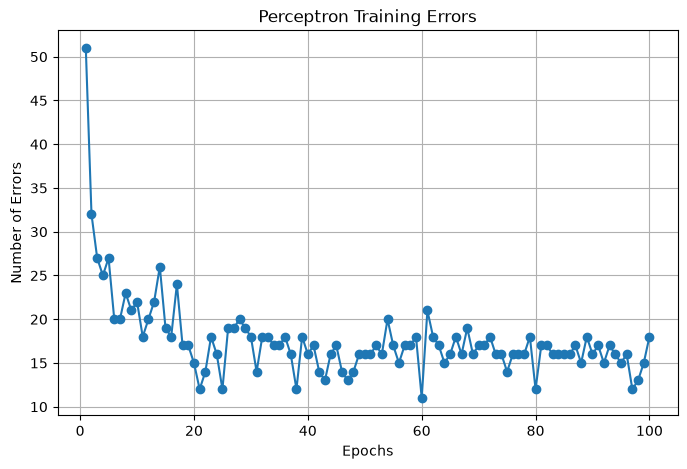

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(perceptron.errors) + 1),
         perceptron.errors,
         marker='o')
plt.title("Perceptron Training Errors")
plt.xlabel("Epochs")
plt.ylabel("Number of Errors")
plt.grid(True)
plt.show()

In [14]:
y_pred = perceptron.predict(X_test)
print("Actual Values:")
print(y_test[:20])
print("\nPredicted Values:")
print(y_pred[:20])

Actual Values:
[0 1 0 1 1 1 0 0 0 1 0 1 0 0 0 0 1 1 1 0]

Predicted Values:
[0 1 0 1 1 1 0 0 0 1 0 1 0 0 0 0 1 1 1 0]


In [15]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print("Model Performance")
print("-------------------------")
print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1-Score:  {f1 * 100:.2f}%")

Model Performance
-------------------------
Accuracy:  98.55%
Precision: 96.83%
Recall:    100.00%
F1-Score:  98.39%


In [16]:
print(classification_report ( y_test, y_pred, target_names=["Genuine", "Forged"] ))

              precision    recall  f1-score   support

     Genuine       1.00      0.97      0.99       153
      Forged       0.97      1.00      0.98       122

    accuracy                           0.99       275
   macro avg       0.98      0.99      0.99       275
weighted avg       0.99      0.99      0.99       275



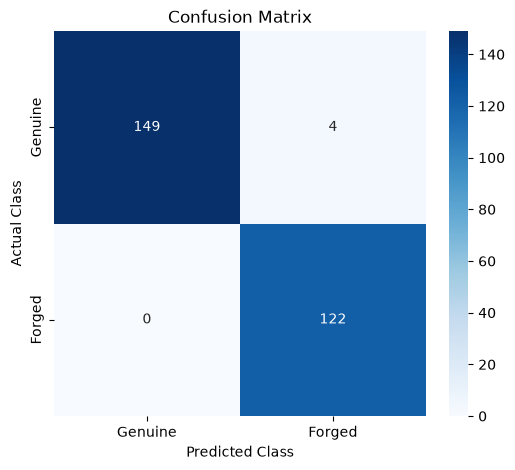

In [17]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Genuine', 'Forged'],
    yticklabels=['Genuine', 'Forged']
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [18]:
print("FINAL SINGLE-LAYER PERCEPTRON RESULTS")
print("=" * 40)
print("Dataset: Banknote Authentication")
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Learning Rate:", perceptron.learning_rate)
print("Epochs:", perceptron.epochs)
print("\nFinal Weights:")
print(perceptron.weights)
print("\nFinal Bias:")
print(perceptron.bias)
print("\nAccuracy: {:.2f}%".format(accuracy * 100))
print("Precision: {:.2f}%".format(precision * 100))
print("Recall: {:.2f}%".format(recall * 100))
print("F1-Score: {:.2f}%".format(f1 * 100))

FINAL SINGLE-LAYER PERCEPTRON RESULTS
Dataset: Banknote Authentication
Training Samples: 1097
Testing Samples: 275
Learning Rate: 0.01
Epochs: 100

Final Weights:
[-0.22298399 -0.26903532 -0.24649669 -0.00438611]

Final Bias:
-0.10999999999999999

Accuracy: 98.55%
Precision: 96.83%
Recall: 100.00%
F1-Score: 98.39%


In [ ]:
import flask
print("Flask installed successfully!")
print("Flask version:", flask.__version__)

Flask installed successfully!
Flask version: 3.1.3


C:\Users\hp\AppData\Local\Temp\ipykernel_18588\2806114066.py:4: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Flask 3.2. Use feature detection or 'importlib.metadata.version("flask")' instead.
  print("Flask version:", flask.__version__)


In [20]:
from flask import Flask, request, render_template_string
app = Flask(__name__)

In [21]:
html_page = """
<!DOCTYPE html>
<html>
<head>
    <title>Banknote Authentication</title>
    <style>
        body {
            font-family: Arial;
            background: #f1f4f9;
            text-align: center;
            padding: 40px;
        }
        .container {
            background: white;
            width: 400px;
            margin: auto;
            padding: 30px;
            border-radius: 12px;
            box-shadow: 0 0 10px #ccc;
        }
        input {
            width: 90%;
            padding: 10px;
            margin: 8px;
            border: 1px solid #ccc;
            border-radius: 5px;
        }
        button {
            background: #2563eb;
            color: white;
            padding: 12px 25px;
            border: none;
            border-radius: 5px;
            cursor: pointer;
        }
        button:hover {
            background: #1d4ed8;
        }
        .result {
            margin-top: 20px;
            font-size: 18px;
            font-weight: bold;
        }
    </style>
</head>
<body>
<div class="container">
    <h2>Banknote Authentication</h2>
    <p>Single-Layer Perceptron Prediction</p>
    <form method="POST">
        <input type="number" step="any" name="variance"
        placeholder="Variance" required>
        <input type="number" step="any" name="skewness"
        placeholder="Skewness" required>
        <input type="number" step="any" name="curtosis"
        placeholder="Curtosis" required>
        <input type="number" step="any" name="entropy"
        placeholder="Entropy" required>
        <button type="submit">Predict</button>
    </form>
    {% if result %}
        <div class="result">
            Prediction: {{ result }}
        </div>
    {% endif %}
    {% if error %}
        <div class="result" style="color:red">
            {{ error }}
        </div>
    {% endif %}
</div>
</body>
</html>
"""

In [22]:
@app.route('/', methods=['GET', 'POST'])
def home():
    result = None
    error = None
    if request.method == 'POST':
        try:
            variance = float(request.form['variance'])
            skewness = float(request.form['skewness'])
            curtosis = float(request.form['curtosis'])
            entropy = float(request.form['entropy'])
            input_data = np.array([[
                variance,
                skewness,
                curtosis,
                entropy
            ]])
            scaled_input = scaler.transform(input_data)
            prediction = perceptron.predict(scaled_input)[0]
            if prediction == 0:
                result = "Genuine Banknote"
            else:
                result = "Forged Banknote"
        except ValueError:
            error = "Please enter valid numerical values."
    return render_template_string(
        html_page,
        result=result,
        error=error
    )

In [ ]:
import threading
def run_flask():
    app.run(host='127.0.0.1', port=5000, debug=False, use_reloader=False)
flask_thread = threading.Thread(target=run_flask, daemon=True)
flask_thread.start()

 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit
127.0.0.1 - - [31/Oct/2026 23:25:07] "GET /?utm_source=chatgpt.com HTTP/1.1" 200 -
127.0.0.1 - - [31/Oct/2026 23:25:08] "GET /favicon.ico HTTP/1.1" 404 -
127.0.0.1 - - [31/Oct/2026 23:25:34] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [31/Oct/2026 23:26:26] "POST / HTTP/1.1" 200 -


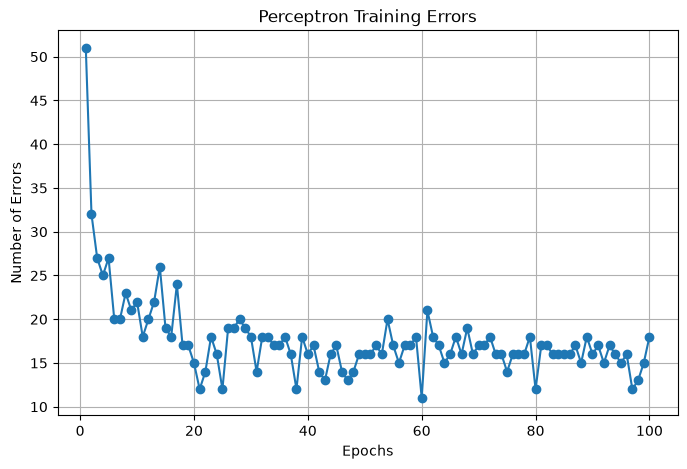

In [24]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(perceptron.errors) + 1),
         perceptron.errors,
         marker='o')
plt.title("Perceptron Training Errors")
plt.xlabel("Epochs")
plt.ylabel("Number of Errors")
plt.grid(True)
plt.savefig("training_errors.png", dpi=300, bbox_inches="tight")
plt.show()

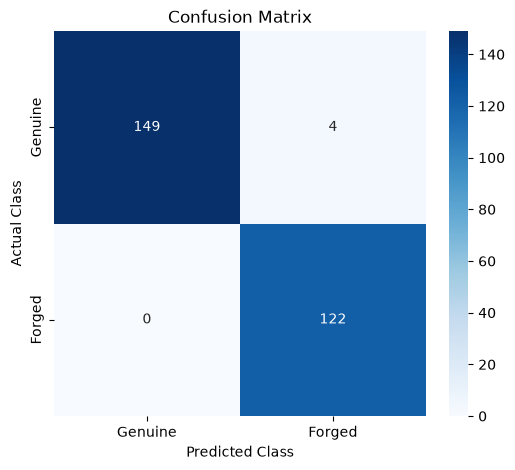

In [25]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Genuine', 'Forged'],
    yticklabels=['Genuine', 'Forged']
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()